# Sigma Calibration Analysis

Analyses `data/calibration_results.csv` produced by `scripts/calibration_harness.py`.

1. **Inlier ratio vs error** — is inlier_ratio a useful predictor of error?
2. **Stanford plot** — sigma_m vs error_m (is sigma calibrated?)
3. **Error map** — spatial distribution of errors on the map
4. **Bucket table** — inlier_ratio → calibrated sigma (p68) lookup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/calibration_results.csv")
ok = df[df["ok"] == True].copy()
print(f"Total: {len(df)},  OK: {len(ok)},  No-fix: {len(df) - len(ok)}")
ok.describe()

Total: 200,  OK: 164,  No-fix: 36


,true_x,true_y,true_lat,true_lon,true_heading_deg,est_lat,est_lon,est_heading_rad,sigma_m,n_inliers,inlier_ratio,error_m
count,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000
mean,4157.378049,2676.268293,51.068209,13.720276,180.817807,51.068205,13.720275,0.009805,0.231707,68.762195,0.649553,0.733134
std,2036.156542,1101.348165,0.004855,0.014284,109.894552,0.004848,0.014285,1.799222,0.116047,48.269675,0.114039,6.791401
min,604.000000,634.000000,51.060213,13.695348,1.866551,51.060212,13.695348,-3.121140,0.200000,4.000000,0.266700,0.012000
25%,2575.500000,1779.000000,51.063671,13.709178,90.273906,51.063683,13.709176,-1.333861,0.200000,33.000000,0.580925,0.092250
50%,3930.000000,2619.500000,51.068460,13.718681,180.069258,51.068461,13.718683,0.009457,0.200000,58.500000,0.666700,0.156000
75%,6148.000000,3705.750000,51.072165,13.734240,281.632030,51.072165,13.734241,1.574289,0.200000,94.250000,0.726775,0.221500
max,7571.000000,4490.000000,51.077213,13.744223,359.186575,51.077214,13.744224,3.123968,1.000000,222.000000,0.860500,87.107000


## 1. Inlier ratio vs error

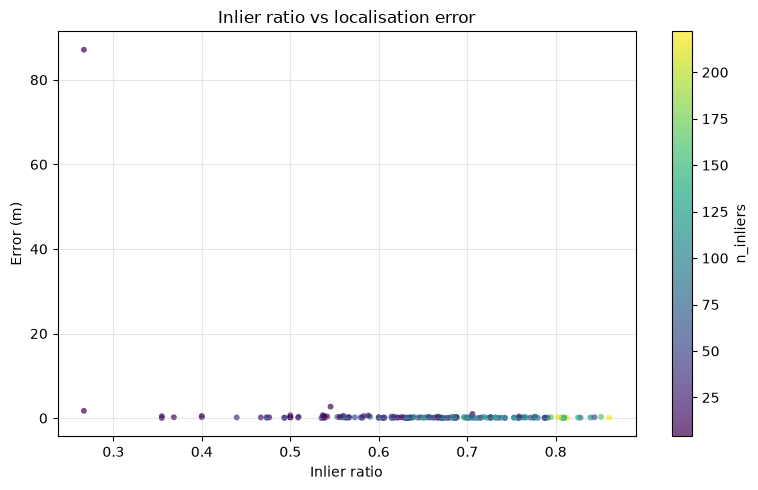

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(ok["inlier_ratio"], ok["error_m"], c=ok["n_inliers"],
                cmap="viridis", s=18, alpha=0.7, edgecolors="none")
ax.set_xlabel("Inlier ratio")
ax.set_ylabel("Error (m)")
ax.set_title("Inlier ratio vs localisation error")
plt.colorbar(sc, label="n_inliers")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Stanford plot (sigma vs error)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
lim = 3.0
ax.plot([0, lim], [0, lim], "k--", linewidth=1, label="sigma = error")
ax.scatter(ok["sigma_m"], ok["error_m"], s=18, alpha=0.6, edgecolors="none")
ax.set_xlabel("Reported sigma (m)")
ax.set_ylabel("True error (m)")
ax.set_title("Stanford plot — sigma calibration")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Error map

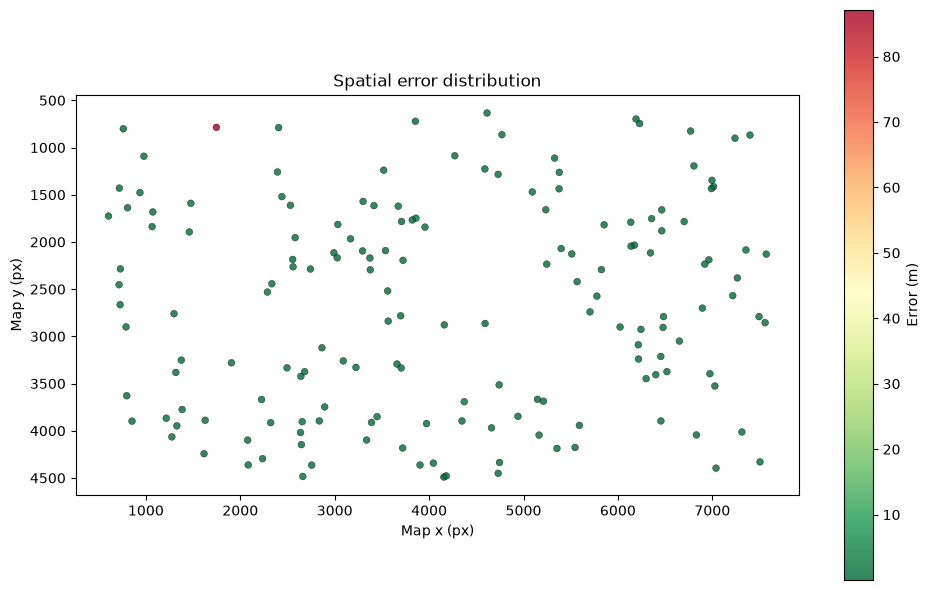

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(ok["true_x"], ok["true_y"], c=ok["error_m"],
                cmap="RdYlGn_r", s=24, alpha=0.8, edgecolors="k", linewidths=0.3)
ax.set_xlabel("Map x (px)")
ax.set_ylabel("Map y (px)")
ax.set_title("Spatial error distribution")
ax.invert_yaxis()
plt.colorbar(sc, label="Error (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 4. Inlier-ratio bucket table → calibrated sigma lookup

In [5]:
bins = [0, 0.15, 0.25, 0.35, 0.5, 1.01]
labels = ["0–0.15", "0.15–0.25", "0.25–0.35", "0.35–0.50", "0.50+"]
ok["bucket"] = pd.cut(ok["inlier_ratio"], bins=bins, labels=labels, right=False)

table = ok.groupby("bucket", observed=False)["error_m"].agg(
    count="count",
    median_error="median",
    p68_error=lambda s: np.percentile(s, 68) if len(s) else np.nan,
    p95_error=lambda s: np.percentile(s, 95) if len(s) else np.nan,
)
table = table.round(2)
print("Inlier-ratio bucket table")
print("=" * 60)
print(table.to_string())
print()
print("Calibrated sigma lookup (p68 error per bucket):")
for label, row in table.iterrows():
    print(f"  inlier_ratio {label:>10s}  →  sigma = {row['p68_error']:.2f} m  (n={int(row['count'])})")

Inlier-ratio bucket table
           count  median_error  p68_error  p95_error
bucket                                              
0–0.15         0           NaN        NaN        NaN
0.15–0.25      0           NaN        NaN        NaN
0.25–0.35      2         44.42      59.79      82.84
0.35–0.50     12          0.18       0.21       0.49
0.50+        150          0.15       0.19       0.44

Calibrated sigma lookup (p68 error per bucket):
  inlier_ratio     0–0.15  →  sigma = nan m  (n=0)
  inlier_ratio  0.15–0.25  →  sigma = nan m  (n=0)
  inlier_ratio  0.25–0.35  →  sigma = 59.79 m  (n=2)
  inlier_ratio  0.35–0.50  →  sigma = 0.21 m  (n=12)
  inlier_ratio      0.50+  →  sigma = 0.19 m  (n=150)
